Dataset 1: California house prices  

In [2]:
# importing necessary libraries
import numpy as np
import pandas as pd  
import matplotlib.pyplot as plt 
import seaborn as sns  


## Part 1-Data Collection

In [3]:
# importing datasets
df=pd.read_csv("housing.csv")
print(df.head(5))
print(df.shape)
df.isna().sum()

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  
(20640, 10)


longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [4]:
df['total_bedrooms']=df['total_bedrooms'].fillna(df['total_bedrooms'].mean())
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [5]:
df.isna().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

In [6]:
# Remove duplicates
df.duplicated().sum()

np.int64(0)

## Part 3-Normalization

In [7]:
# Normalization 
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in df.columns if c not in numeric_cols]
X_num=df[numeric_cols].copy()
# log 2 transformation
X_log2 = np.log2(X_num + 1.0)
# z-score normalization
X_log2_z = (X_log2 - X_log2.mean()) / X_log2.std(ddof=0)
normalized_df=pd.concat([X_log2_z, df[cat_cols]], axis=1)

d:\Microinformatics projects\venv\Lib\site-packages\pandas\core\internals\blocks.py:395: RuntimeWarning: invalid value encountered in log2
  result = func(self.values, **kwargs)


## Part 4-Visualization

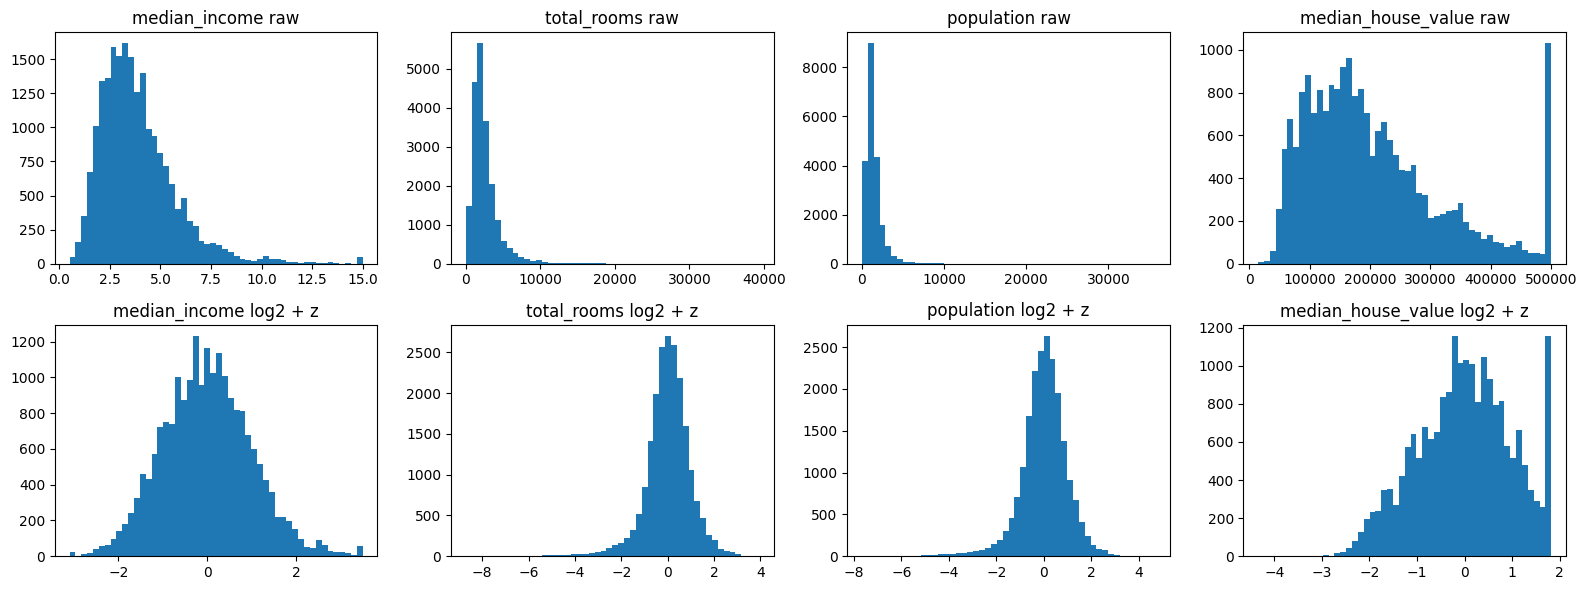

In [8]:

# Quick distribution check for a few key columns
plot_cols = [c for c in ['median_income', 'total_rooms', 'population', 'median_house_value'] if c in numeric_cols]
plot_cols = plot_cols[:4]

fig, axes = plt.subplots(2, len(plot_cols), figsize=(4 * len(plot_cols), 6))
if len(plot_cols) == 1:
    axes = np.array([[axes[0]], [axes[1]]])

for idx, col in enumerate(plot_cols):
    axes[0, idx].hist(X_num[col].dropna(), bins=50)
    axes[0, idx].set_title(col + ' raw')
    axes[1, idx].hist(X_log2_z[col].dropna(), bins=50)
    axes[1, idx].set_title(col + ' log2 + z')

plt.tight_layout()
plt.show()

In [9]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

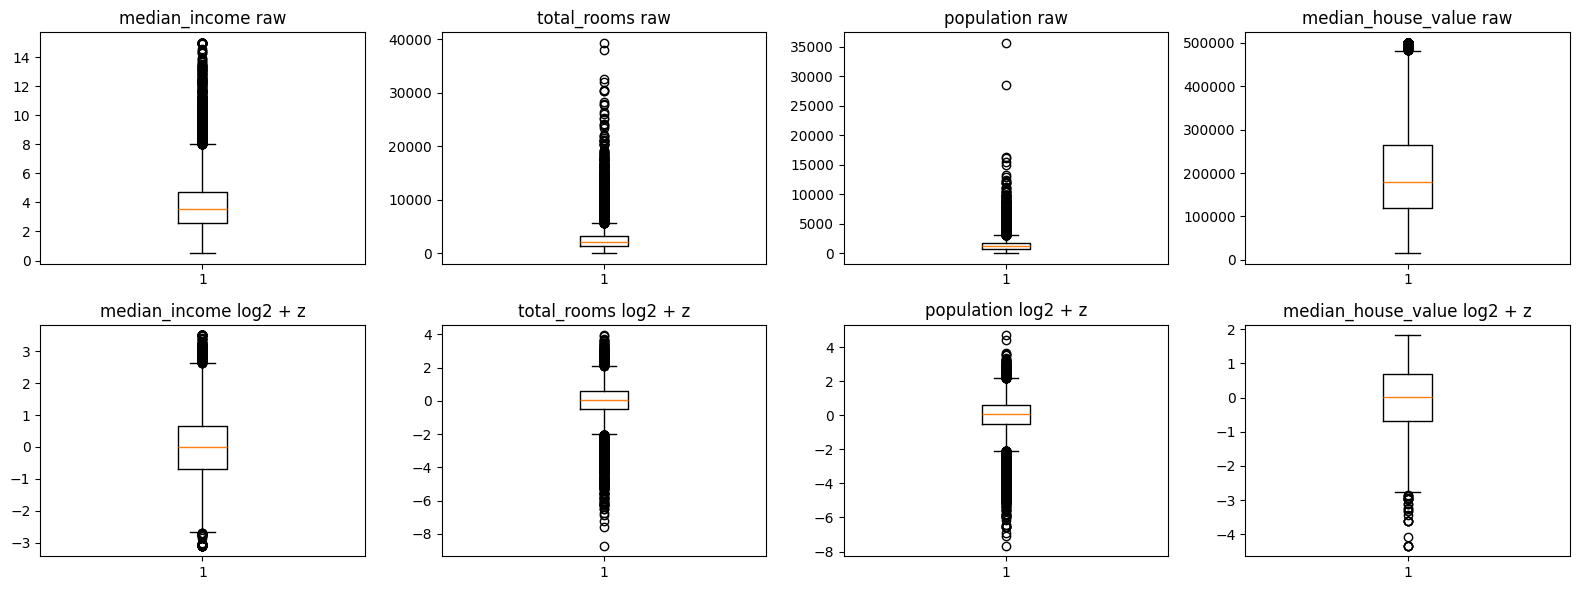

In [10]:

# Quick distribution check for a few key columns
plot_cols = [c for c in ['median_income', 'total_rooms', 'population', 'median_house_value'] if c in numeric_cols]
plot_cols = plot_cols[:4]

fig, axes = plt.subplots(2, len(plot_cols), figsize=(4 * len(plot_cols), 6))
if len(plot_cols) == 1:
    axes = np.array([[axes[0]], [axes[1]]])

for idx, col in enumerate(plot_cols):
    axes[0, idx].boxplot(X_num[col].dropna())
    axes[0, idx].set_title(col + ' raw')
    axes[1, idx].boxplot(X_log2_z[col].dropna())
    axes[1, idx].set_title(col + ' log2 + z')

plt.tight_layout()
plt.show()

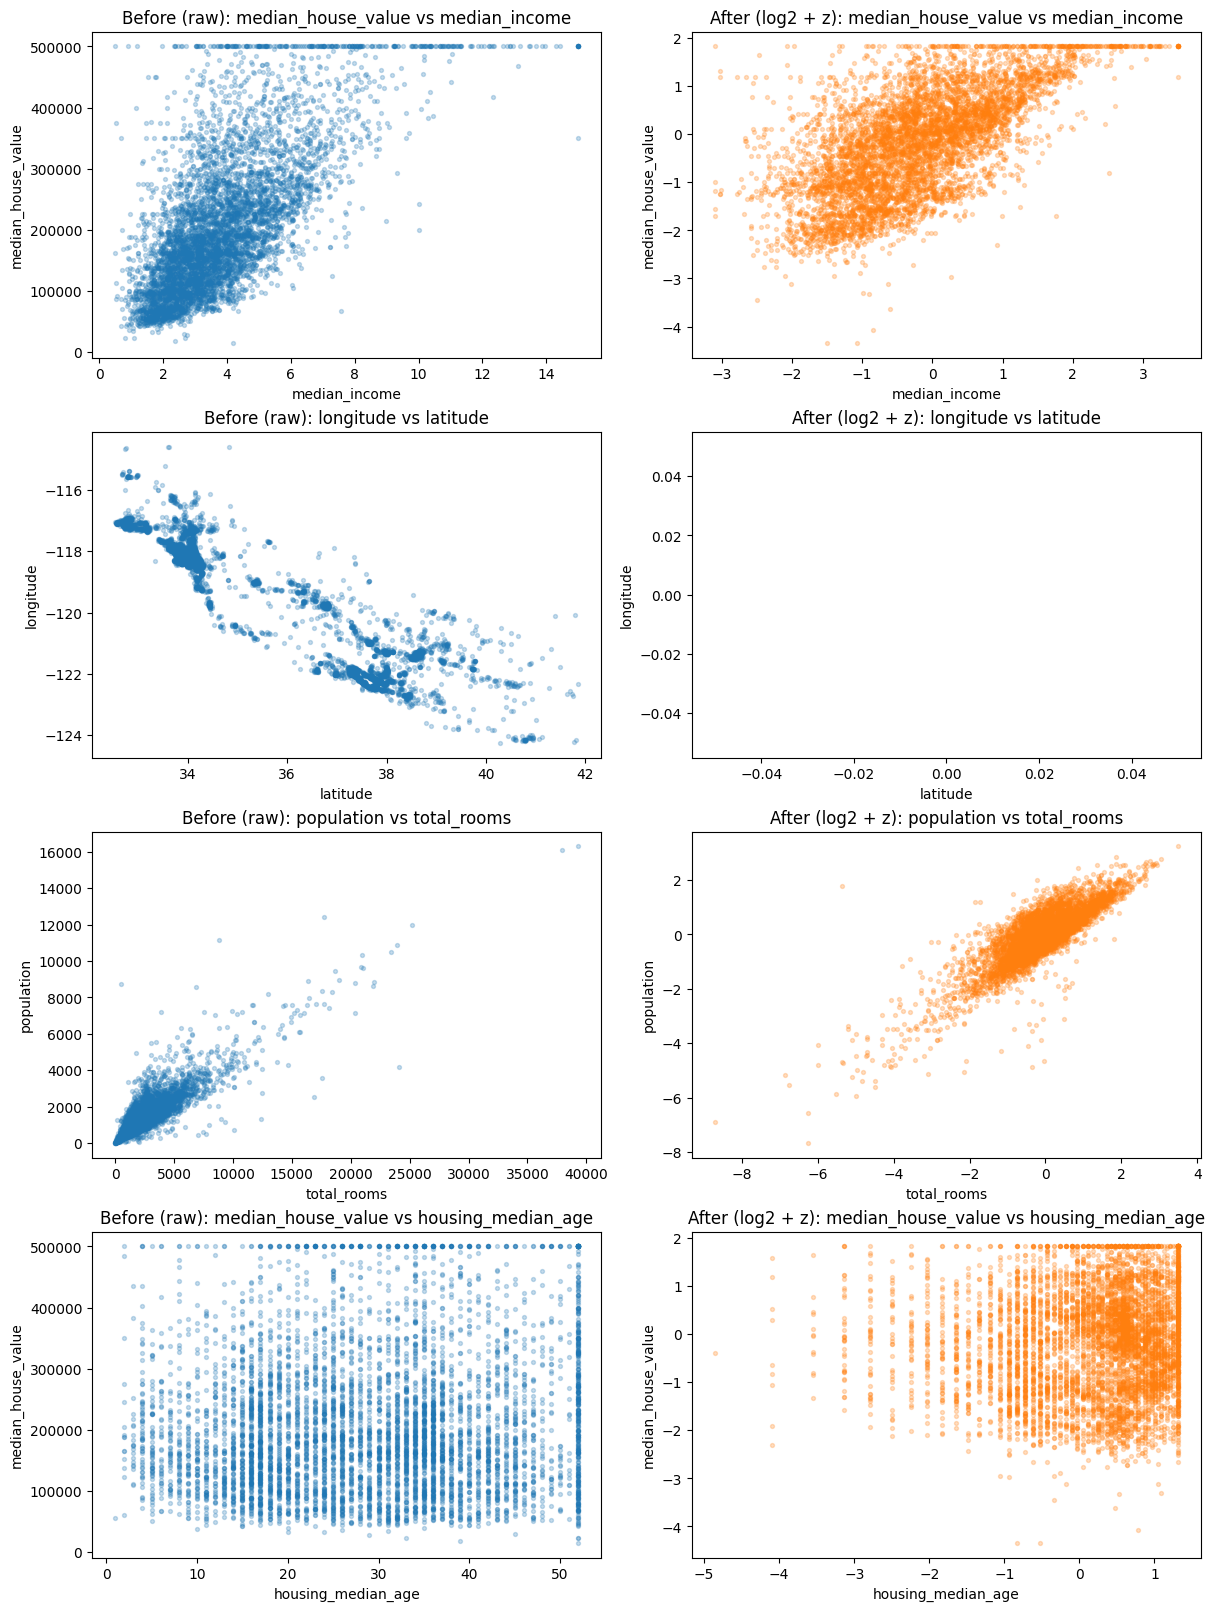

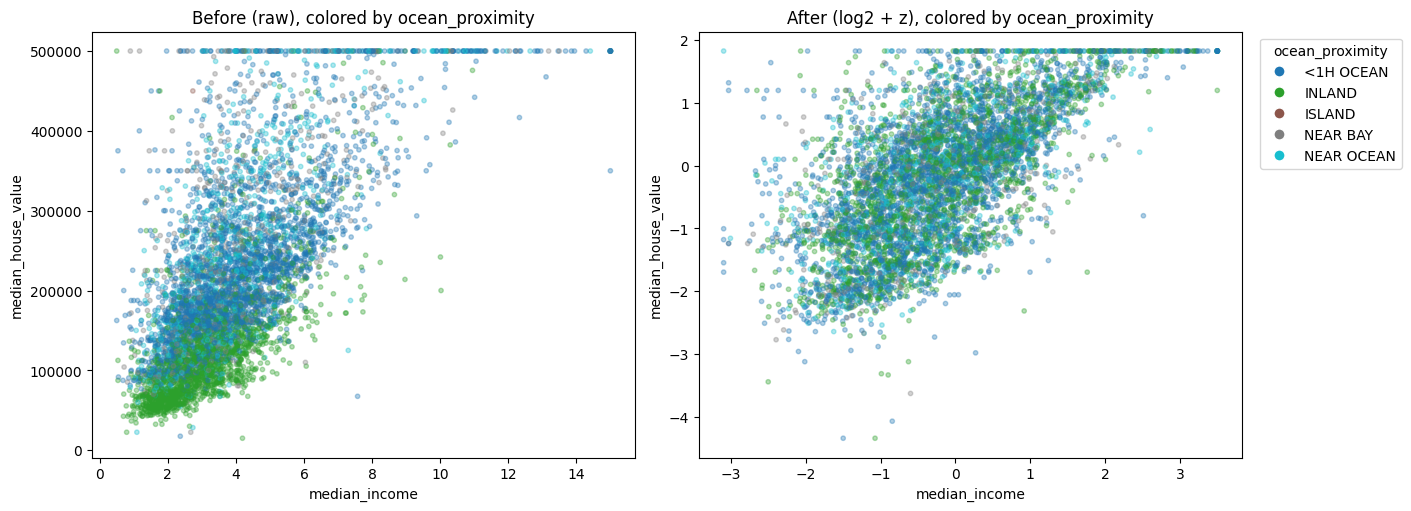

In [11]:
# Create before/after scatter plots (raw vs log2+z) for key feature pairs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use existing dataframes if available; otherwise fall back to reading from disk
try:
    df
except NameError:
    df = pd.read_csv('housing.csv')

try:
    normalized_df
except NameError:
    numeric_cols_fallback = df.select_dtypes(include=[np.number]).columns.tolist()
    X_num_fallback = df[numeric_cols_fallback].copy()
    X_log2_fallback = np.log2(X_num_fallback + 1.0)
    X_log2_z_fallback = (X_log2_fallback - X_log2_fallback.mean()) / X_log2_fallback.std(ddof=0)
    cat_cols_fallback = [c for c in df.columns if c not in numeric_cols_fallback]
    housing_log2norm_df = pd.concat([X_log2_z_fallback, df[cat_cols_fallback]], axis=1)

# Pick common scatter pairs for housing dataset
pairs = [
    ('median_income', 'median_house_value'),
    ('latitude', 'longitude'),
    ('total_rooms', 'population'),
    ('housing_median_age', 'median_house_value')
]

# Only keep pairs that exist
pairs = [(x, y) for (x, y) in pairs if x in df.columns and y in df.columns]

# Sample to keep plots fast but representative
n_plot = min(6000, len(df))
plot_df_raw = df.sample(n=n_plot, random_state=42).reset_index(drop=True)
plot_df_norm = normalized_df.loc[plot_df_raw.index].reset_index(drop=True)

# Create a grid: each pair has before and after side-by-side
n_pairs = len(pairs)
fig, axes = plt.subplots(n_pairs, 2, figsize=(12, 4 * n_pairs), constrained_layout=True)
if n_pairs == 1:
    axes = np.array([axes])

for i, (xcol, ycol) in enumerate(pairs):
    ax_before = axes[i, 0]
    ax_after = axes[i, 1]

    ax_before.scatter(plot_df_raw[xcol], plot_df_raw[ycol], s=8, alpha=0.25)
    ax_before.set_title('Before (raw): ' + ycol + ' vs ' + xcol)
    ax_before.set_xlabel(xcol)
    ax_before.set_ylabel(ycol)

    ax_after.scatter(plot_df_norm[xcol], plot_df_norm[ycol], s=8, alpha=0.25, color='tab:orange')
    ax_after.set_title('After (log2 + z): ' + ycol + ' vs ' + xcol)
    ax_after.set_xlabel(xcol)
    ax_after.set_ylabel(ycol)

plt.show()

# Also: color the main relationship by ocean_proximity (before/after) to see structure
if 'ocean_proximity' in df.columns and 'median_income' in df.columns and 'median_house_value' in df.columns:
    fig2, axes2 = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
    cats = plot_df_raw['ocean_proximity'].astype('category')
    codes = cats.cat.codes

    sc0 = axes2[0].scatter(plot_df_raw['median_income'], plot_df_raw['median_house_value'], c=codes, cmap='tab10', s=10, alpha=0.35)
    axes2[0].set_title('Before (raw), colored by ocean_proximity')
    axes2[0].set_xlabel('median_income')
    axes2[0].set_ylabel('median_house_value')

    sc1 = axes2[1].scatter(plot_df_norm['median_income'], plot_df_norm['median_house_value'], c=codes, cmap='tab10', s=10, alpha=0.35)
    axes2[1].set_title('After (log2 + z), colored by ocean_proximity')
    axes2[1].set_xlabel('median_income')
    axes2[1].set_ylabel('median_house_value')

    # Legend
    handles = []
    labels = []
    for cat_name, cat_code in zip(cats.cat.categories, range(len(cats.cat.categories))):
        handles.append(plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=plt.cm.tab10(cat_code / max(1, len(cats.cat.categories)-1)), markersize=8))
        labels.append(str(cat_name))
    axes2[1].legend(handles, labels, title='ocean_proximity', bbox_to_anchor=(1.02, 1), loc='upper left')

    plt.show()

## Part 5-Exploratory Data Analysis (EDA)

In [12]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,419.266592,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,297.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,438.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,643.250000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


Here are some values that are outliers in their respective column like in Households feature the outlier is 6000 and as shown in below boxplot


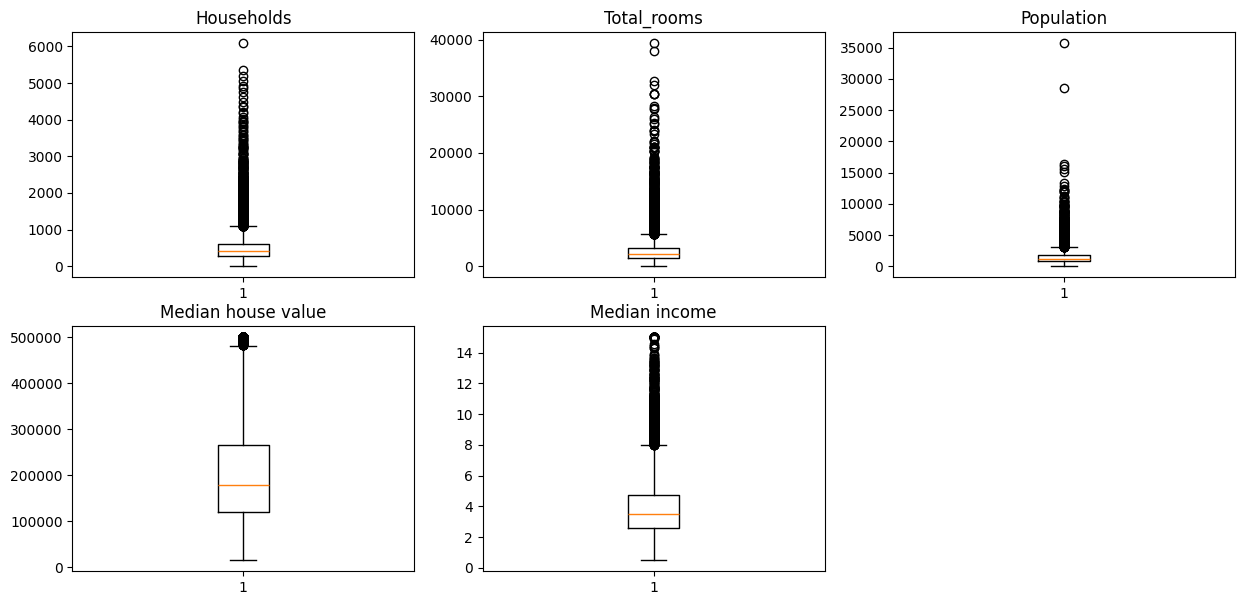

In [13]:
# correlation matrix
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
new_df=df.drop('ocean_proximity',axis=1)
correlation_matrix=new_df.corr() 

correlation_matrix
# outliers detection 
plt.figure(figsize=(15,7)) 
plt.subplot(2,3,1)
plt.title("Households")
plt.boxplot(df['households'])
plt.subplot(2,3,2)
plt.title("Total_rooms")
plt.boxplot(df['total_rooms'])
plt.subplot(2,3,3)
plt.title("Population")
plt.boxplot(df['population'])
plt.subplot(2,3,4)
plt.title("Median house value")
plt.boxplot(df['median_house_value'])
plt.subplot(2,3,5)
plt.title("Median income")
plt.boxplot(df['median_income'])
print(f"Here are some values that are outliers in their respective column like in Households feature the outlier is 6000 and as shown in below boxplot")

In [14]:
import pandas as pd

corr = df.corr(numeric_only=True)
print(corr['median_house_value'].sort_values(ascending=False))

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049454
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


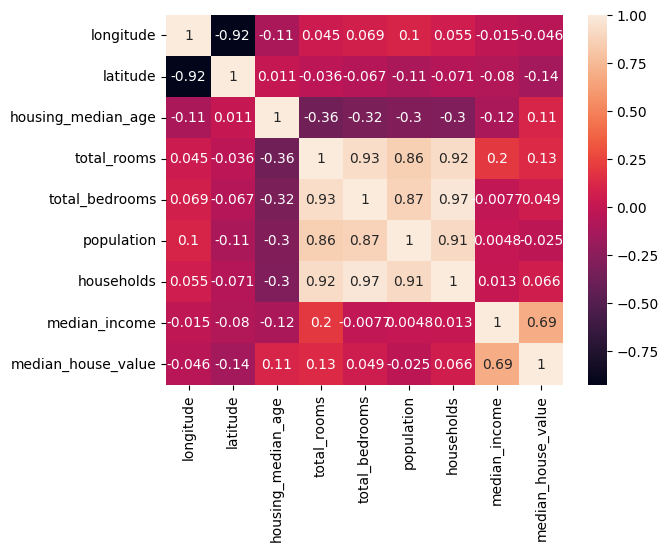

median income has high impact on house price as more purchasing power more prices 


In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(df.corr(numeric_only=True), annot=True) 
plt.show()
print(f"median income has high impact on house price as more purchasing power more prices ")

## Data analysis of california house prediction has been completed 